# GRANAP in metafspm: cross sections as a component

In metafspm, GRANAP is a component, `GranapAnatomy`: it gives every segment of a plant its cross-section anatomy,
written into the plant graph as **Compartments** (cells, walls, wall junctions) and **Connections** (the network
between them). Other models (MECHA's hydraulics, solutes) read them from there.

It is used like any metafspm component, as in Wheat-BRIDGES: a plant model assembles components, a planting table
gives each plant a **scenario**, and the scenario's `parameters` override the components' defaults.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.metafspm.coupling.composite_wrapper import CompositeModel
from openalea.metafspm.coupling.translator import Translator
from openalea.metafspm.scene.scene import Scene

from openalea.granap.metafspm.architectures import Needle, RootAxis
from openalea.granap.metafspm.component import GranapAnatomy, junction_rules
from openalea.granap.metafspm.plots import draw_section, draw_sections

## 1. A plant model with GRANAP's anatomies

The plant model is a `CompositeModel`:
- `initiators` build each plant: an architecture first (here `RootAxis`, a stand-in giving each segment its radius,
  length and distance from the tip), then `GranapAnatomy`, which generates the segments' anatomies;
- `from_scale`, `nodes`, `wiring`: the DataStructure's nodes are the Compartments of the segments' anatomies, and
  GRANAP's `junction_rules` join the xylem and phloem of successive sections;
- `__init__` instantiates the components on the DataStructure and couples them; `run` is one time step.

In [2]:
class RootAnatomies(CompositeModel):
    initiators = (RootAxis, GranapAnatomy)
    from_scale, nodes, wiring = "SubOrgan", "Compartment", junction_rules

    def __init__(self, data_structure, time_step):
        anatomy = self.initiators[-1]                                   # GranapAnatomy, or a subclass of it
        self.anatomy = anatomy(data_structure=data_structure, time_step=time_step)
        self.declare_data_and_couple_components(translator_path=Translator(), components=(self.anatomy,))

    def run(self):
        self.anatomy()                       # anatomies for the new or changed segments


def plants(model, *scenarios):
    """A planting table: one plant per scenario."""
    return pd.DataFrame([dict(plant=f"plant {i}", model=model, x=float(i), y=0., z=0., rotation=0.,
                              scenario={"parameters": parameters}) for i, parameters in enumerate(scenarios)])

## 2. One section

One plant, the default scenario: one root segment, GRANAP's monocot root preset.

8269 Compartments, 20334 Connections


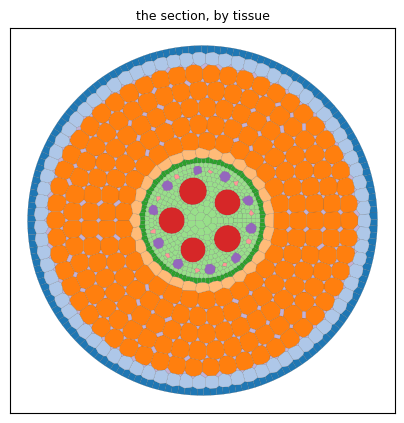

In [3]:
scene = Scene(plants(RootAnatomies, {}))
ds = scene.populations[0].data_structure
print(f"{ds.n_nodes()} Compartments, {ds.n_edges()} Connections")

segment = int(ds.entity_ids("SubOrgan")[0])
fig, ax = plt.subplots(figsize=(5, 5))
draw_section(ax, ds, segment, title="the section, by tissue")
plt.show()

The component's outputs are variables of the DataStructure, one value per Compartment or Connection:

In [4]:
one_of_each = [int((ds.get("kind") == k).argmax()) for k in (0, 1, 2)]       # a protoplast, a wall, a junction
pd.DataFrame({name: ds.get(name)[one_of_each] for name in ("kind", "tissue", "cgroup", "cell_area", "wall_length",
                                                            "section_x", "section_y")})

,kind,tissue,cgroup,cell_area,wall_length,section_x,section_y
0,0.0,epidermis,2.0,0.000247,0.000000,0.401890,-0.004997
1,1.0,NaN,NaN,0.000000,0.017477,0.401273,-0.012307
2,2.0,NaN,NaN,0.000000,0.000000,-0.410254,-0.002622


In [5]:
pd.Series(ds.get("tissue")[ds.get("kind") == 0]).value_counts()

stele         406
air space     367
cortex        206
epidermis     168
pericycle      97
exodermis      79
endodermis     32
protoxylem     10
phloem         10
metaxylem       5
Name: count, dtype: int64

## 3. Parametrizing: the scenario

GRANAP's parameters are its `OrganInputData` sections and fields. In a scenario, one dict per kind of segment
overrides them, on top of a preset:

| key | segments | default preset |
|---|---|---|
| `root_anatomy` | root segments | `for_root` |
| `stem_anatomy` | stem elements | `for_monocot_stem` |
| `leaf_anatomy` | leaf elements | `for_monocot_leaf` |

Each dict: `"preset"` (any `OrganInputData` preset), `"seed"`, and `{section: {field: value}}`. Five plants, five
scenarios, in one scene:

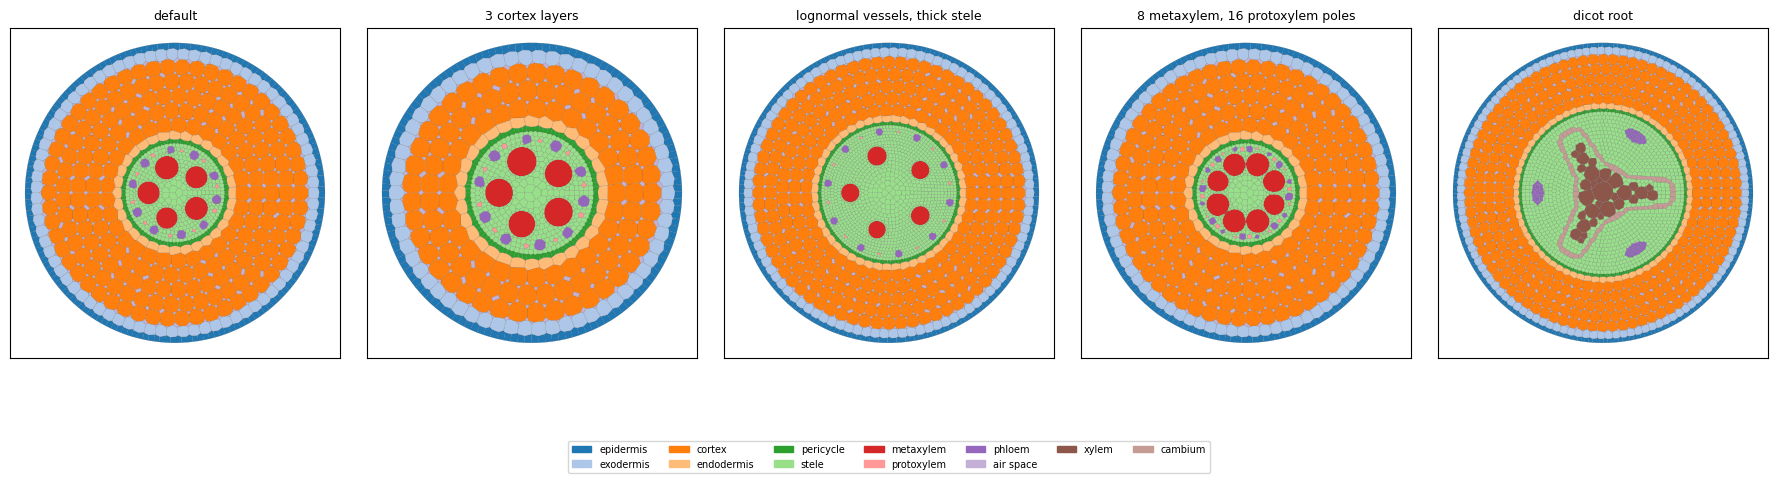

In [6]:
scenarios = {
    "default": {},
    "3 cortex layers": {"root_anatomy": {"cortex": {"n_layers": 3}}},
    "lognormal vessels, thick stele": {"root_anatomy": {"stele": {"thickness": 0.45},
                                                       "xylem": {"vessel_diameter_distribution": {"family": "lognormal"}}}},
    "8 metaxylem, 16 protoxylem poles": {"root_anatomy": {"xylem": {"n_vascular_bundles": 8, "n_protoxylem": 16}}},
    "dicot root": {"root_anatomy": {"preset": "for_dicot_root"}},
}
scene = Scene(plants(RootAnatomies, *scenarios.values()))
fig = draw_sections(scene.populations[0].data_structure, titles=list(scenarios), columns=5)
plt.show()

The leaves are generated when the scenario gives `leaf_anatomy`; its preset chooses GRANAP's organ class
(`for_needle`: the needle). The `Needle` architecture stand-in reads its own keys from the same scenario.

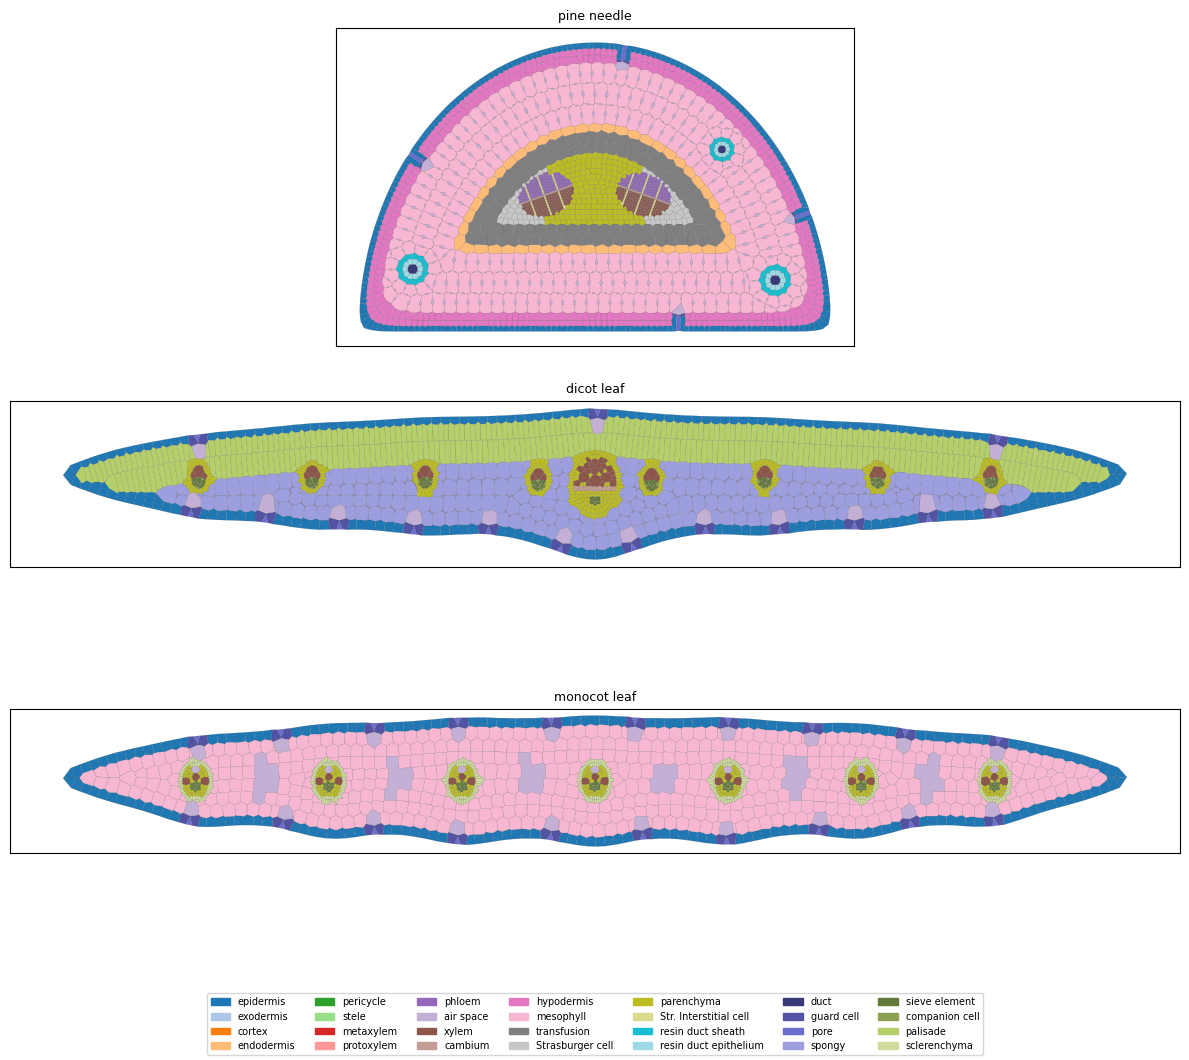

In [7]:
class LeafAnatomies(RootAnatomies):
    initiators = (Needle, GranapAnatomy)


leaves = {"pine needle": {"leaf_anatomy": {"preset": "for_needle", "seed": 42}},
          "dicot leaf": {"leaf_anatomy": {"preset": "for_dicot_leaf"}},
          "monocot leaf": {"leaf_anatomy": {"preset": "for_monocot_leaf"}}}
scene = Scene(plants(LeafAnatomies, *leaves.values()))
fig = draw_sections(scene.populations[0].data_structure, titles=list(leaves), columns=1, panel=(12, 3.2))
plt.show()

## 4. Several anatomies within a plant

Within a plant, the segments of a kind are grouped into **classes** by their diameter (bins of 0.05 mm): one
anatomy is generated per class and copied onto its segments. A root of four segments, two diameters: two
templates, four copies.

In [8]:
axis = {"root_segments": [[0.55e-3, 2e-4, 0.03], [0.55e-3, 2e-4, 0.02], [0.40e-3, 2e-4, 0.01], [0.40e-3, 2e-4, 0.]]}
scene = Scene(plants(RootAnatomies, axis))
ds = scene.populations[0].data_structure
g = ds.mtg
print({int(s): g.property("anatomy_class")[int(s)] for s in ds.entity_ids("SubOrgan")})
print("templates:", len(set(g.property("anatomy_template").values())), "for", len(ds.entity_ids("SubOrgan")),
      "segments")

{16: (1.1, 0.0, 0.0), 17: (1.1, 0.0, 0.0), 18: (0.8, 0.0, 0.0), 19: (0.8, 0.0, 0.0)}
templates: 2 for 4 segments


The diameter is only the class's key: the scenario's dict applies to every class alike. To make the anatomy
itself depend on the class (thinner roots with fewer cortex layers, aerenchyma with age), the advanced hook is a
class attribute, `root` (or `shoot`), an `OrganAnatomy` with its own class inputs and per-class parameters; see the
docstring of `GranapAnatomy` and `test/component/test_class_inputs.py`.

## 5. How the sections are joined axially

The anatomies of successive segments are joined by **axial junctions**: Connections (`network_path` 5) between the
conducting cells of a section and those of the next. The DataStructure creates them from the model's `wiring`,
GRANAP's `junction_rules(g)`: two rules, one per family of conduits, each a function
`rule(g, parent, child, parent_compartments, child_compartments) -> [(a, b), ...]`:

- xylem to xylem (apoplastic junctions), phloem to phloem (symplastic junctions);
- paired by their tracked vessel id where both have one (a root series), else each to the nearest of the other
  section in both directions (in angle and relative radius), so that a fusion or a split gives one-to-many pairs.

Which two segments are joined comes from a **multiscale traversal** of the plant graph: each segment is joined to
its *linked parent* at the `SubOrgan` scale (`g.linked_parent(segment, scale)`): its parent segment along the
axis; for the first segment of a lateral, the bearer's segment it branches on, although the two belong to
different axes and organs; when a segment has no parent at its own scale, the tip segment of the nearest complex
parent (an organ, an axis) above it.

A root of three segments, and a thinner lateral of two branched on its second segment. So that the lateral's
anatomy differs (two metaxylem, a narrower stele), this example uses section 4's advanced hook once: an
`OrganAnatomy` for the roots whose thinner classes (diameter under 0.9 mm) get their own parameters.

In [9]:
from openalea.granap.metafspm.component import OrganAnatomy
from openalea.granap.metafspm.library import AnatomyLibrary


class RootSystemAnatomy(GranapAnatomy):
    root = OrganAnatomy(AnatomyLibrary(class_parameters=lambda key: {
        "xylem": {"n_vascular_bundles": 2, "n_protoxylem": 4}, "stele": {"thickness": 0.12}} if key[0] < 0.9 else {}))


class RootSystem(RootAnatomies):
    initiators = (RootAxis, RootSystemAnatomy)


root_system = {"root_segments": [[0.55e-3, 2e-4, 0.02], [0.55e-3, 2e-4, 0.01], [0.55e-3, 2e-4, 0.]],
               "root_laterals": [[1, [[0.3e-3, 2e-4, 0.002], [0.3e-3, 2e-4, 0.]]]]}
scene = Scene(plants(RootSystem, root_system))
ds = scene.populations[0].data_structure
g = ds.mtg
view, owner, tissue = ds.to_graph_view(), ds.owner("SubOrgan"), ds.get("tissue")
segments = ds.entity_ids("SubOrgan")
junction = ds.get("network_path") == 5
xylem_tissues = ("metaxylem", "protoxylem", "xylem")
rows = []
for i, segment in enumerate(segments):
    parent = g.linked_parent(int(segment), g.scales.SubOrgan)
    into = junction & (owner[view.head] == i)                        # n_id_b (head): the child side
    rows.append({"segment": int(segment), "axis": int(g.complex_at_scale(int(segment), g.scales.Axis)),
                 "linked parent": parent,
                 "xylem junctions": int((into & np.isin(tissue[view.head], xylem_tissues)).sum()),
                 "phloem junctions": int((into & (tissue[view.head] == "phloem")).sum())})
pd.DataFrame(rows).set_index("segment")

,axis,linked parent,xylem junctions,phloem junctions
segment,,,,
16,12,NaN,0,0
17,12,16.0,15,10
18,12,17.0,15,10
23,19,17.0,16,10
24,19,23.0,6,4


Each pair as a line, the parent's section on the left, the child's on the right: along the main axis, the same
template on both sides gives one-to-one pairs; from the main root to its lateral, each of the lateral's fewer
vessels joins several of the main root's (and each of the main root's joins its nearest in the lateral).

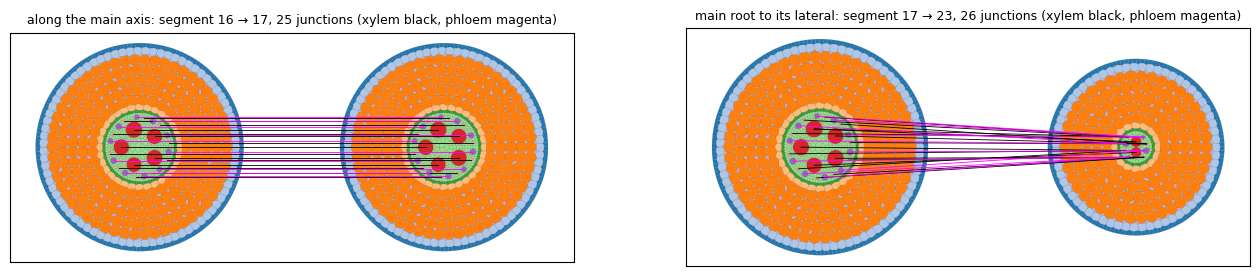

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
pairs = {"along the main axis": (segments[0], segments[1]), "main root to its lateral": (segments[1], segments[3])}
for ax, (title, (parent, child)) in zip(axes, pairs.items()):
    shift = (1.2, 0.)
    draw_section(ax, ds, parent)
    draw_section(ax, ds, child, offset=shift)
    i_parent, i_child = list(segments).index(parent), list(segments).index(child)
    e = np.flatnonzero(junction & (owner[view.tail] == i_parent) & (owner[view.head] == i_child))
    x, y = ds.get("section_x"), ds.get("section_y")
    for family, colour in ((xylem_tissues, "black"), (("phloem",), "magenta")):
        chosen = e[np.isin(tissue[view.tail[e]], family)]
        ax.plot(np.c_[x[view.tail[chosen]], x[view.head[chosen]] + shift[0]].T,
                np.c_[y[view.tail[chosen]], y[view.head[chosen]] + shift[1]].T, color=colour, lw=0.6)
    ax.set_title(f"{title}: segment {parent} → {child}, {e.size} junctions (xylem black, phloem magenta)", fontsize=9)
plt.show()

## 6. Following growth

When the architecture model adds a segment, the component gives it its anatomy at the next step; the DataStructure
rewires the new section to its neighbours: its junctions to its linked parent. Here the lateral grows one segment
at its tip, by hand:

In [11]:
tip = int(segments[-1])                                               # the lateral's tip
new = g.add_child(tip, edge_type="<", label=g.labels.SubOrgan.RootSegment)
g.property("radius")[new], g.property("length")[new], g.property("distance_from_tip")[new] = 0.3e-3, 2e-4, 0.
scene.run()
print("new segment:", scene.populations[0].instance.anatomy.last_update, "- its linked parent:",
      g.linked_parent(new, g.scales.SubOrgan), f"- {int((ds.get('network_path') == 5).sum())} axial junctions now")

new segment: {'emerged': [124910], 'replaced': []} - its linked parent: 24 - 86 axial junctions now


Next: MECHA's tutorials (`MECHA-dev/example/tutorials`), which add the hydraulics to these anatomies.